# 📊 Analisis Performa Postingan & Social Engagement Instagram (@zahiraccounting)
**Zahir Social Analytics — Fase 5.5: Instagram Social Engagement & Content Performance Analysis**  
*Reproducible Data Science & Analytical Pipeline*

---

## 📌 1. Pendahuluan & Ringkasan Eksekutif
Notebook ini menyajikan analisis komprehensif terhadap performa keterlibatan (*engagement*) dari **55 postingan publik Instagram** akun `@zahiraccounting` yang telah diproses secara kanonikal pada **Fase 5.4** (`data/final/instagram_posts_final.csv`).

### Metodologi & Batasan Tata Kelola Data:
1. **Integritas Sumber Data (*Immutable Source*)**: Dataset sumber berisi tepat 55 postingan unik tanpa perubahan byte pada sumber data kanonikal.
2. **Keterlibatan Riil (*Zero Synthetic Fabrication*)**: Metrik `views` tetap bernilai `NaN` sesuai fakta web publik Instagram unauthenticated. Analisis berfokus murni pada tindakan pengguna terverifikasi: $\text{total\_interactions} = \text{likes} + \text{comments}$. Tidak ada pembagian fiktif untuk mengarang *engagement rate percentage*, *reach*, *impressions*, atau estimasi *followers*.
3. **Kewaspadaan Ukuran Sampel (*Sample Size Caution*)**: Distribusi format didominasi oleh video/reel ($80.0\%$, $n=44$) dibandingkan carousel ($14.5\%$, $n=8$) dan image ($5.5\%$, $n=3$). Setiap inferensi komparatif mencantumkan peringatan ukuran sampel.
4. **Pemisahan Korelasi dan Sebab-Akibat (*Non-Causal Inference*)**: Hubungan antara kolaborasi, waktu posting, caption, atau hashtag tidak diinterpretasikan sebagai hubungan kausal mutlak tanpa bukti eksperimental terkontrol.


In [1]:
# Setup Lingkungan & Import Library
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi Tampilan & Visualisasi
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = ['Calibri', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

print("[OK] Library analisis & visualisasi berhasil dimuat.")


[OK] Library analisis & visualisasi berhasil dimuat.


## 📁 2. Pemuatan Dataset Final & Verifikasi Skema
Dataset dimuat dari `data/final/instagram_posts_final.csv`. Seluruh 55 baris diverifikasi keunikannya.


In [2]:
# Pemuatan Dataset Final Fase 5.4
DATA_PATH = os.path.join('..', 'data', 'final', 'instagram_posts_final.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'final', 'instagram_posts_final.csv')

df = pd.read_csv(DATA_PATH)
print(f"📊 Dataset dimuat: {df.shape[0]} baris, {df.shape[1]} kolom.")
assert len(df) == 55, f"Jumlah baris tidak valid: {len(df)}"
assert df['post_id'].nunique() == 55, "Terdapat duplikasi post_id!"

# Tampilkan 5 baris pertama
display_cols = ['post_id', 'post_date', 'content_type', 'is_collaboration', 'original_account', 'likes', 'comments', 'total_interactions']
df[display_cols].head()


📊 Dataset dimuat: 55 baris, 27 kolom.


,post_id,post_date,content_type,is_collaboration,original_account,likes,comments,total_interactions
0,Dbr2KN3gZjt,2026-08-06,carousel,False,zahiraccounting,4,0,4
1,DbGd0k0kuz4,2026-07-22,carousel,True,muhamad.is,34,2,36
2,DaKhtzOAeP1,2026-06-29,carousel,False,zahiraccounting,31,9,40
3,DaCQc-LEkwR,2026-06-26,carousel,True,muhamad.is,331,11,342
4,DZ7GcGdgVon,2026-06-23,carousel,False,zahiraccounting,13,12,25


## 📈 3. Analisis Engagement per Postingan & Distribusi Keseluruhan
Menghitung likes, comments, dan `total_interactions = likes + comments`. Menganalisis parameter tendensi sentral (mean, median), dispersi (std, IQR), serta mendeteksi pencilan (*outliers*) menggunakan kriteria Tukey IQR ($Q3 + 1.5 \times IQR$).


In [3]:
# Perhitungan Ringkasan Statistik Engagement
summary_stats = []
for col in ['likes', 'comments', 'total_interactions']:
    s = df[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    outlier_thresh = q3 + 1.5 * iqr
    outliers = s[s > outlier_thresh]
    
    summary_stats.append({
        'Metrik': col,
        'N (Posts)': len(s),
        'Total Akumulasi': int(s.sum()),
        'Mean': s.mean(),
        'Std Dev': s.std(),
        'Median': s.median(),
        'Min': int(s.min()),
        'Max': int(s.max()),
        'Q1 (25%)': q1,
        'Q3 (75%)': q3,
        'IQR': iqr,
        'Skewness': s.skew(),
        'Batas Outlier (Q3+1.5*IQR)': outlier_thresh,
        'Jumlah Outlier': len(outliers),
        'Persentase Outlier (%)': len(outliers) / len(s) * 100
    })

df_summary = pd.DataFrame(summary_stats)
print("=== RINGKASAN STATISTIK DESKRIPTIF ENGAGEMENT (N=55) ===")
df_summary


=== RINGKASAN STATISTIK DESKRIPTIF ENGAGEMENT (N=55) ===


,Metrik,N (Posts),Total Akumulasi,Mean,Std Dev,Median,Min,Max,Q1 (25%),Q3 (75%),IQR,Skewness,Batas Outlier (Q3+1.5*IQR),Jumlah Outlier,Persentase Outlier (%)
0,likes,55,12643,229.87,590.43,44.00,1,3191,23.00,109.00,86.00,4.27,238.00,9,16.36
1,comments,55,504,9.16,41.14,1.00,0,306,0.00,6.50,6.50,7.22,16.25,4,7.27
2,total_interactions,55,13147,239.04,618.57,51.00,1,3217,24.00,110.00,86.00,4.31,239.00,9,16.36


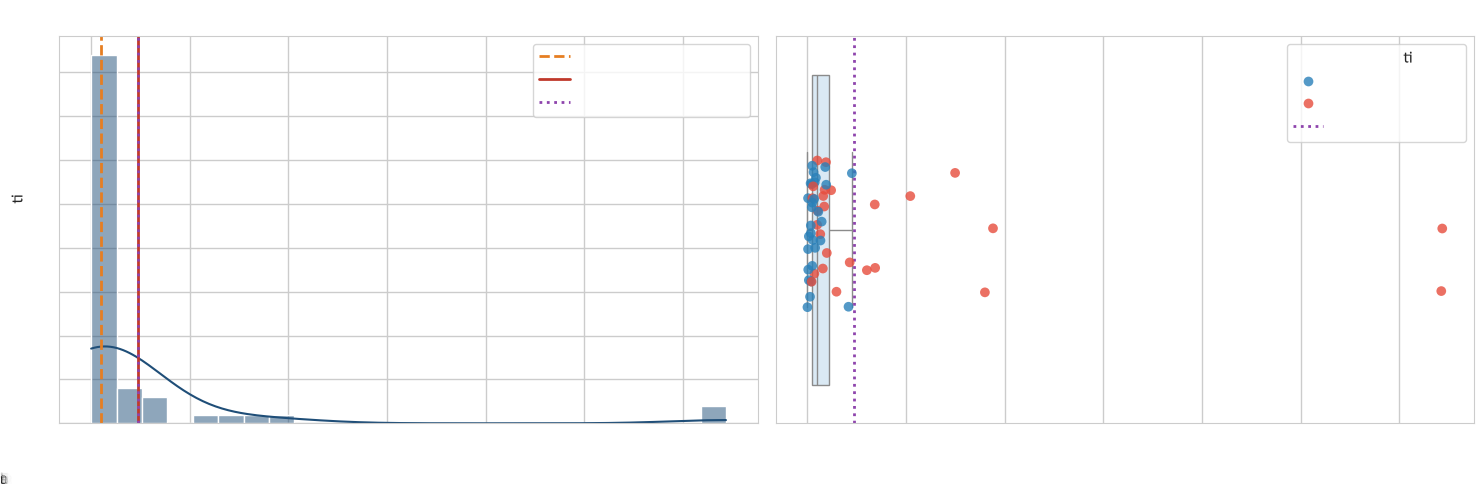

In [4]:
# Visualisasi Distribusi Interaksi & Deteksi Outlier
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Histogram & KDE (Right Skewed Distribution)
sns.histplot(df['total_interactions'], bins=25, kde=True, color='#1F4E78', ax=axes[0], edgecolor='white')
axes[0].axvline(df['total_interactions'].median(), color='#E67E22', linestyle='--', linewidth=2, label=f"Median: {df['total_interactions'].median():.0f}")
axes[0].axvline(df['total_interactions'].mean(), color='#C0392B', linestyle='-', linewidth=2, label=f"Mean: {df['total_interactions'].mean():.1f}")
axes[0].axvline(239.0, color='#8E44AD', linestyle=':', linewidth=2, label="Ambang Outlier IQR: 239.0")
axes[0].set_title("Distribusi Total Interaksi (Right-Skewed Tail, Skew=4.31)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Total Interaksi (Likes + Comments)")
axes[0].set_ylabel("Frekuensi Postingan")
axes[0].legend(frameon=True, facecolor='white')

# 2. Boxplot dengan Sebaran Titik Data
sns.boxplot(x=df['total_interactions'], color='#D6EAF8', ax=axes[1], fliersize=0)
sns.stripplot(x=df['total_interactions'], hue=df['is_collaboration'], palette={False: '#2980B9', True: '#E74C3C'},
              size=7, jitter=0.2, alpha=0.8, ax=axes[1])
axes[1].axvline(239.0, color='#8E44AD', linestyle=':', linewidth=2, label="Batas Outlier (239.0)")
axes[1].set_title("Boxplot Total Interaksi & 9 Viral Outliers", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Total Interaksi")
axes[1].legend(title="Is Collaboration", frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


## 🎭 4. Perbandingan Performa Jenis Konten (Video/Reels vs Carousel vs Image)
Membandingkan ketiga format postingan berdasarkan jumlah tayang, total likes, total komentar, serta mean dan median interaksi.

> **Catatan Keterbatasan Inferensi**: Terdapat asimetri tajam dalam distribusi format konten pada akun `@zahiraccounting`:
> - `video/reel`: 44 postingan ($80.0\%$)
> - `carousel`: 8 postingan ($14.5\%$)
> - `image`: 3 postingan ($5.5\%$)
> Ukuran sampel gambar tunggal ($n=3$) terlalu kecil untuk generalisasi statistik. Perbandingan harus ditekankan pada metrik median dan distribusi interquartil.


In [5]:
# Perhitungan Agregat per Jenis Konten
ct_comparison = df.groupby('content_type').agg(
    post_count=('post_id', 'count'),
    total_likes=('likes', 'sum'),
    mean_likes=('likes', 'mean'),
    median_likes=('likes', 'median'),
    total_comments=('comments', 'sum'),
    mean_comments=('comments', 'mean'),
    median_comments=('comments', 'median'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    std_interactions=('total_interactions', 'std'),
    min_interactions=('total_interactions', 'min'),
    max_interactions=('total_interactions', 'max')
).reset_index()

ct_comparison['post_share_pct'] = (ct_comparison['post_count'] / len(df) * 100)
ct_comparison = ct_comparison[['content_type', 'post_count', 'post_share_pct', 'total_likes', 'mean_likes', 'median_likes',
                               'total_comments', 'mean_comments', 'median_comments', 'total_interactions',
                               'mean_interactions', 'median_interactions', 'std_interactions', 'min_interactions', 'max_interactions']]

print("=== PERBANDINGAN PERFORMA FORMAT KONTEN ===")
ct_comparison


=== PERBANDINGAN PERFORMA FORMAT KONTEN ===


,content_type,post_count,post_share_pct,total_likes,mean_likes,median_likes,total_comments,mean_comments,median_comments,total_interactions,mean_interactions,median_interactions,std_interactions,min_interactions,max_interactions
0,carousel,8,14.55,588,73.50,33.00,70,8.75,10.00,658,82.25,45.00,108.40,4,342
1,image,3,5.45,15,5.00,5.00,2,0.67,0.00,17,5.67,5.00,2.08,4,8
2,video/reel,44,80.00,12040,273.64,55.00,432,9.82,0.50,12472,283.45,61.50,684.25,1,3217


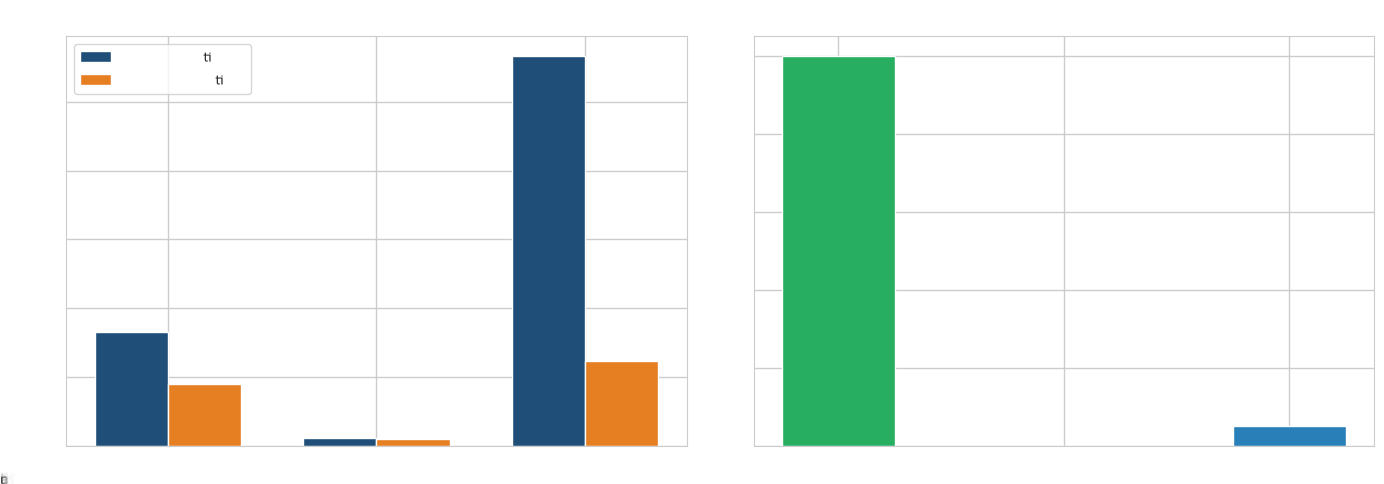

In [6]:
# Visualisasi Performa Antar Format Konten
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Perbandingan Mean vs Median Total Interaksi
bar_width = 0.35
indices = np.arange(len(ct_comparison))

axes[0].bar(indices - bar_width/2, ct_comparison['mean_interactions'], width=bar_width, label='Mean Interactions', color='#1F4E78')
axes[0].bar(indices + bar_width/2, ct_comparison['median_interactions'], width=bar_width, label='Median Interactions', color='#E67E22')
axes[0].set_xticks(indices)
axes[0].set_xticklabels(ct_comparison['content_type'], fontweight='bold')
axes[0].set_title("Mean vs Median Interaksi per Format Konten", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Interaksi")
axes[0].legend(frameon=True, facecolor='white')

# 2. Pola Percakapan: Rasio Komentar per Format
comment_ratios = df.groupby('content_type')['comments'].median()
axes[1].bar(comment_ratios.index, comment_ratios.values, color=['#27AE60', '#95A5A6', '#2980B9'], edgecolor='white', width=0.5)
axes[1].set_title("Median Komentar per Format (Carousel Mendorong Diskusi)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel("Median Komentar")
for i, v in enumerate(comment_ratios.values):
    axes[1].text(i, v + 0.3, f"{v:.1f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 🤝 5. Analisis Konten Kolaborasi (*Collaboration Impact Analysis*)
Mengevaluasi perbedaan engagement antara postingan organik mandiri `@zahiraccounting` ($n=29$) dengan postingan kolaborasi co-author ($n=26$).

> **Penegasan Tata Kelola Metodologis**:
> - Peningkatan engagement pada konten kolaborasi **bukan bukti kausal mutlak** bahwa kolaborasi pasti menyebabkan virality.
> - Efek ini dipengaruhi oleh faktor perancu (*confounding factors*): basis followers akun mitra (misal: `@pecahtelur.id` dengan audiens wirausaha massal), format video wawancara, waktu penayangan, serta proses kurasi konten berkualitas tinggi sebelum diajak kolaborasi.


In [7]:
# Analisis Statistik Kolaborasi
colab_stats = df.groupby('is_collaboration').agg(
    post_count=('post_id', 'count'),
    total_likes=('likes', 'sum'),
    mean_likes=('likes', 'mean'),
    median_likes=('likes', 'median'),
    total_comments=('comments', 'sum'),
    mean_comments=('comments', 'mean'),
    median_comments=('comments', 'median'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    std_interactions=('total_interactions', 'std'),
    min_interactions=('total_interactions', 'min'),
    max_interactions=('total_interactions', 'max')
).reset_index()

colab_stats['post_share_pct'] = (colab_stats['post_count'] / len(df) * 100)
colab_stats['label'] = colab_stats['is_collaboration'].map({False: 'Organik (@zahiraccounting)', True: 'Kolaborasi (Mitra / Co-author)'})

print("=== PERBANDINGAN ORGANIK VS KOLABORASI ===")
display(colab_stats[['label', 'post_count', 'post_share_pct', 'total_interactions', 'mean_interactions', 'median_interactions', 'min_interactions', 'max_interactions']])

# Rincian per Akun Mitra
print("\n=== PERINCIAN PER AKUN MITRA ===")
acc_summary = df.groupby(['original_account', 'is_collaboration']).agg(
    post_count=('post_id', 'count'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    max_interactions=('total_interactions', 'max')
).reset_index().sort_values(by='total_interactions', ascending=False)
display(acc_summary)


=== PERBANDINGAN ORGANIK VS KOLABORASI ===


,label,post_count,post_share_pct,total_interactions,mean_interactions,median_interactions,min_interactions,max_interactions
0,Organik (@zahiraccounting),29,52.73,1273,43.90,25.00,1,226
1,Kolaborasi (Mitra / Co-author),26,47.27,11874,456.69,97.00,22,3217



=== PERINCIAN PER AKUN MITRA ===


,original_account,is_collaboration,post_count,total_interactions,mean_interactions,median_interactions,max_interactions
2,pecahtelur.id,True,8,7058,882.25,635.50,3212
1,muhamad.is,True,14,4688,334.86,90.50,3217
3,zahiraccounting,False,29,1273,43.90,25.00,226
5,zahironlineid,True,2,52,26.00,26.00,30
4,zahirerp,True,1,50,50.00,50.00,50
0,modalngobrol,True,1,26,26.00,26.00,26


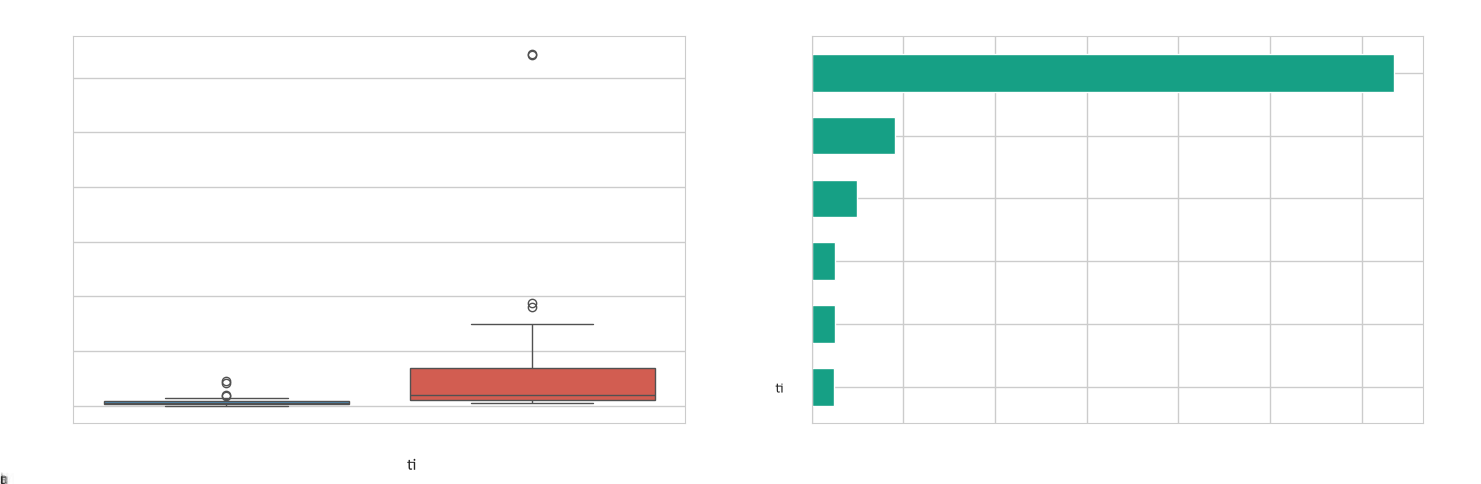

In [8]:
# Visualisasi Performa Kolaborasi & Akun Mitra
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Boxplot Distribusi Interaksi Organik vs Kolaborasi
sns.boxplot(x='is_collaboration', y='total_interactions', data=df, palette=['#3498DB', '#E74C3C'], ax=axes[0])
axes[0].set_xticklabels(['Organik (N=29)', 'Kolaborasi (N=26)'], fontweight='bold')
axes[0].set_title("Distribusi Interaksi: Organik vs Kolaborasi", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Total Interaksi")

# 2. Bar Chart Rata-rata & Median Interaksi per Akun Mitra
acc_sorted = acc_summary.sort_values(by='median_interactions', ascending=True)
axes[1].barh(acc_sorted['original_account'], acc_sorted['median_interactions'], color='#16A085', edgecolor='white', height=0.6)
axes[1].set_title("Median Interaksi per Akun Mitra (Kekuatan Jangkauan @pecahtelur.id)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Median Total Interaksi")
for i, v in enumerate(acc_sorted['median_interactions']):
    axes[1].text(v + 15, i, f"{v:.1f} (N={acc_sorted['post_count'].iloc[i]})", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


## ⏰ 6. Analisis Dinamika Waktu Publikasi (*Temporal Posting Dynamics*)
Mengevaluasi performa interaksi berdasarkan:
1. `post_day_of_week` (Senin - Minggu)
2. `time_bin` (Morning, Afternoon, Late Afternoon, Evening/Night)
3. `post_year` (2024, 2025, 2026)

> **Peringatan Artefak & Confounding Time**:
> - Jam tayang pagi (06:00 WIB) menunjukkan rata-rata interaksi sangat tinggi ($586.8$).
> - Namun, audit granular membuktikan bahwa seluruh lonjakan pagi terkonsentrasi pada kampanye wawancara video kolaborasi `@pecahtelur.id` pada Desember 2024 (5 dari 8 postingannya tayang jam 06:00 WIB).
> - Oleh karena itu, jam 06:00 WIB tidak boleh diartikan sebagai jam magis untuk konten organik Zahir, melainkan mencerminkan kesuksesan distribusi mitra spesifik.


In [9]:
# Analisis Berdasarkan Hari dalam Seminggu
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_analysis = df.groupby('post_day_of_week').agg(
    post_count=('post_id', 'count'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    min_interactions=('total_interactions', 'min'),
    max_interactions=('total_interactions', 'max')
).reindex(day_order).reset_index()

print("=== DISTRIBUSI & INTERAKSI BERDASARKAN HARI PUBLIKASI ===")
display(day_analysis)

# Analisis Berdasarkan Segmen Waktu Penayangan (Time Bin)
def get_time_bin(hour):
    if 6 <= hour <= 11:
        return 'Morning (06:00-11:59)'
    elif 12 <= hour <= 14:
        return 'Afternoon (12:00-14:59)'
    elif 15 <= hour <= 17:
        return 'Late Afternoon (15:00-17:59)'
    elif 18 <= hour <= 23:
        return 'Evening/Night (18:00-23:59)'
    else:
        return 'Early Morning (00:00-05:59)'

df['time_bin'] = df['post_hour_wib'].apply(get_time_bin)
bin_order = ['Morning (06:00-11:59)', 'Afternoon (12:00-14:59)', 'Late Afternoon (15:00-17:59)', 'Evening/Night (18:00-23:59)']
time_bin_analysis = df.groupby('time_bin').agg(
    post_count=('post_id', 'count'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    min_interactions=('total_interactions', 'min'),
    max_interactions=('total_interactions', 'max')
).reindex(bin_order).reset_index()

print("\n=== DISTRIBUSI & INTERAKSI BERDASARKAN SEGMEN JAM TAYANG ===")
display(time_bin_analysis)


=== DISTRIBUSI & INTERAKSI BERDASARKAN HARI PUBLIKASI ===


,post_day_of_week,post_count,total_interactions,mean_interactions,median_interactions,min_interactions,max_interactions
0,Monday,8,395,49.38,39.00,14,121
1,Tuesday,7,3640,520.00,79.00,5,3217
2,Wednesday,8,720,90.00,24.50,4,522
3,Thursday,12,4256,354.67,73.50,4,3212
4,Friday,16,2737,171.06,61.00,1,900
5,Saturday,3,458,152.67,148.00,8,302
6,Sunday,1,941,941.00,941.00,941,941



=== DISTRIBUSI & INTERAKSI BERDASARKAN SEGMEN JAM TAYANG ===


,time_bin,post_count,total_interactions,mean_interactions,median_interactions,min_interactions,max_interactions
0,Morning (06:00-11:59),19,11149,586.79,209.00,4,3217
1,Afternoon (12:00-14:59),11,459,41.73,50.00,5,88
2,Late Afternoon (15:00-17:59),12,436,36.33,27.00,14,96
3,Evening/Night (18:00-23:59),13,1103,84.85,56.00,1,226


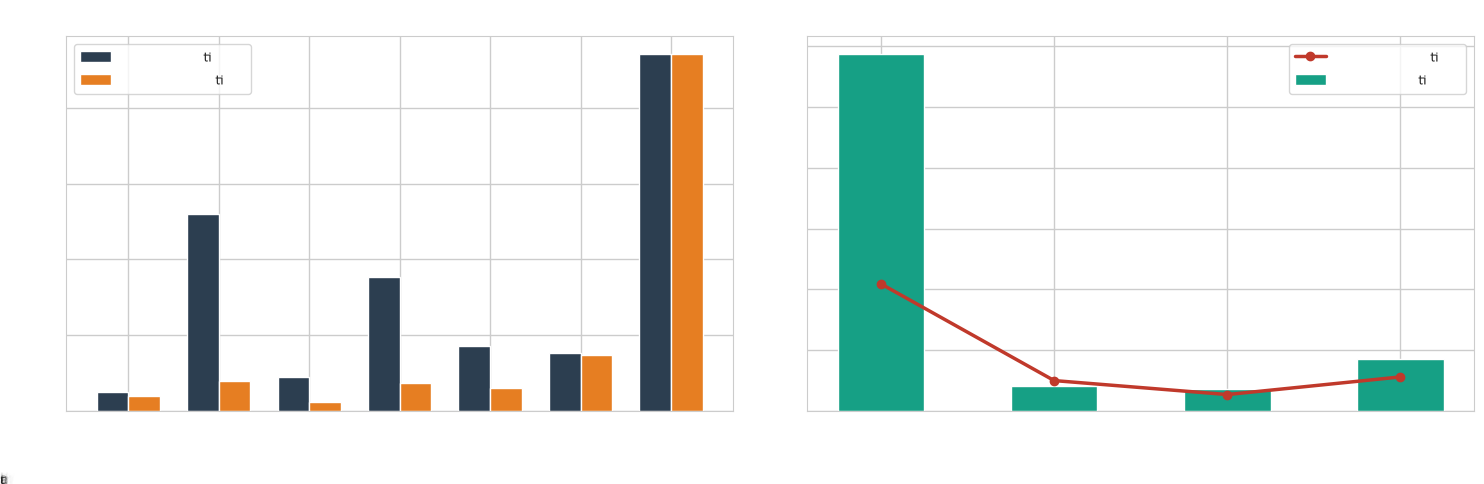

In [10]:
# Visualisasi Dinamika Temporal Publikasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Bar Chart Interaksi per Hari (Mean vs Median)
x = np.arange(len(day_analysis))
w = 0.35
axes[0].bar(x - w/2, day_analysis['mean_interactions'], width=w, label='Mean Interactions', color='#2C3E50')
axes[0].bar(x + w/2, day_analysis['median_interactions'], width=w, label='Median Interactions', color='#E67E22')
axes[0].set_xticks(x)
axes[0].set_xticklabels(day_analysis['post_day_of_week'], rotation=30, ha='right', fontweight='bold')
axes[0].set_title("Interaksi per Hari dalam Seminggu", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Total Interaksi")
axes[0].legend(frameon=True, facecolor='white')

# 2. Segmen Jam Tayang (Time Bin)
axes[1].bar(time_bin_analysis['time_bin'], time_bin_analysis['mean_interactions'], color='#16A085', width=0.5, label='Mean Interactions')
axes[1].plot(time_bin_analysis['time_bin'], time_bin_analysis['median_interactions'], color='#C0392B', marker='o', linewidth=2.5, label='Median Interactions')
axes[1].set_xticklabels(['Pagi (06-11)', 'Siang (12-14)', 'Sore (15-17)', 'Malam (18-23)'], fontweight='bold')
axes[1].set_title("Interaksi Berdasarkan Segmen Waktu (Confounded by @pecahtelur.id)", fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel("Interaksi")
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


## ✍️ 7. Analisis Caption dan Tagar (*Caption Length & Hashtags Efficacy*)
Memeriksa hubungan linier parametrik (Pearson $r$) dan monotonik non-parametrik (Spearman $\rho$) antara jumlah kata caption serta jumlah tagar terhadap total interaksi.

### Temuan Menarik: Simpson's Paradox pada Tagar (#)
- Pada populasi penuh ($N=55$), terdapat korelasi negatif signifikan antara `hashtag_count` dan `total_interactions` (Spearman $\rho = -0.4509$, $p=0.0006$).
- Postingan tanpa tagar (`has_hashtags=False`, $n=16$) memiliki rata-rata interaksi $505.9$ dan median $264.0$, jauh melampaui postingan bertagar ($129.5$, median $38.0$).
- **Namun, ini adalah contoh nyata Simpson's Paradox / Confounder**:
  - Seluruh 8 postingan viral dari mitra `@pecahtelur.id` **sama sekali tidak menyertakan tagar** dalam teks caption aslinya.
  - Sebaliknya, postingan internal akun `@zahiraccounting` yang memiliki jangkauan lebih terbatas secara disiplin menyertakan 4–7 tagar.
  - Saat dianalisis khusus pada postingan organik ($n=29$), korelasi tagar sama sekali tidak signifikan ($ho = -0.158$, $p=0.413$).


In [11]:
# Analisis Korelasi Parametrik & Non-Parametrik
corr_results = []
for var, lbl in [('caption_word_count', 'Jumlah Kata Caption'), ('hashtag_count', 'Jumlah Tagar')]:
    pr, pp = stats.pearsonr(df[var], df['total_interactions'])
    sr, sp = stats.spearmanr(df[var], df['total_interactions'])
    corr_results.append({
        'Variabel': lbl,
        'Pearson r': pr,
        'Pearson p-value': pp,
        'Spearman rho': sr,
        'Spearman p-value': sp,
        'Signifikansi (alpha=0.05)': 'Signifikan' if sp < 0.05 else 'Tidak Signifikan'
    })

print("=== HASIL UJI KORELASI DENGAN TOTAL INTERAKSI (N=55) ===")
display(pd.DataFrame(corr_results))

# Perbandingan Kehadiran Tagar (has_hashtags: True vs False)
ht_comparison = df.groupby('has_hashtags').agg(
    post_count=('post_id', 'count'),
    total_interactions=('total_interactions', 'sum'),
    mean_interactions=('total_interactions', 'mean'),
    median_interactions=('total_interactions', 'median'),
    min_interactions=('total_interactions', 'min'),
    max_interactions=('total_interactions', 'max')
).reset_index()
ht_comparison['status'] = ht_comparison['has_hashtags'].map({False: 'Tanpa Tagar (0 Hashtags)', True: 'Menggunakan Tagar (>=1 Hashtags)'})

u_stat, u_pval = stats.mannwhitneyu(
    df[df['has_hashtags']==True]['total_interactions'],
    df[df['has_hashtags']==False]['total_interactions']
)
print(f"\nUji Mann-Whitney U: Stat = {u_stat:.1f}, p-value = {u_pval:.4f}")
display(ht_comparison[['status', 'post_count', 'total_interactions', 'mean_interactions', 'median_interactions', 'min_interactions', 'max_interactions']])


=== HASIL UJI KORELASI DENGAN TOTAL INTERAKSI (N=55) ===


,Variabel,Pearson r,Pearson p-value,Spearman rho,Spearman p-value,Signifikansi (alpha=0.05)
0,Jumlah Kata Caption,0.38,0.00,0.38,0.00,Signifikan
1,Jumlah Tagar,-0.18,0.19,-0.45,0.00,Signifikan



Uji Mann-Whitney U: Stat = 119.0, p-value = 0.0004


,status,post_count,total_interactions,mean_interactions,median_interactions,min_interactions,max_interactions
0,Tanpa Tagar (0 Hashtags),16,8095,505.94,264.00,18,3212
1,Menggunakan Tagar (>=1 Hashtags),39,5052,129.54,38.00,1,3217


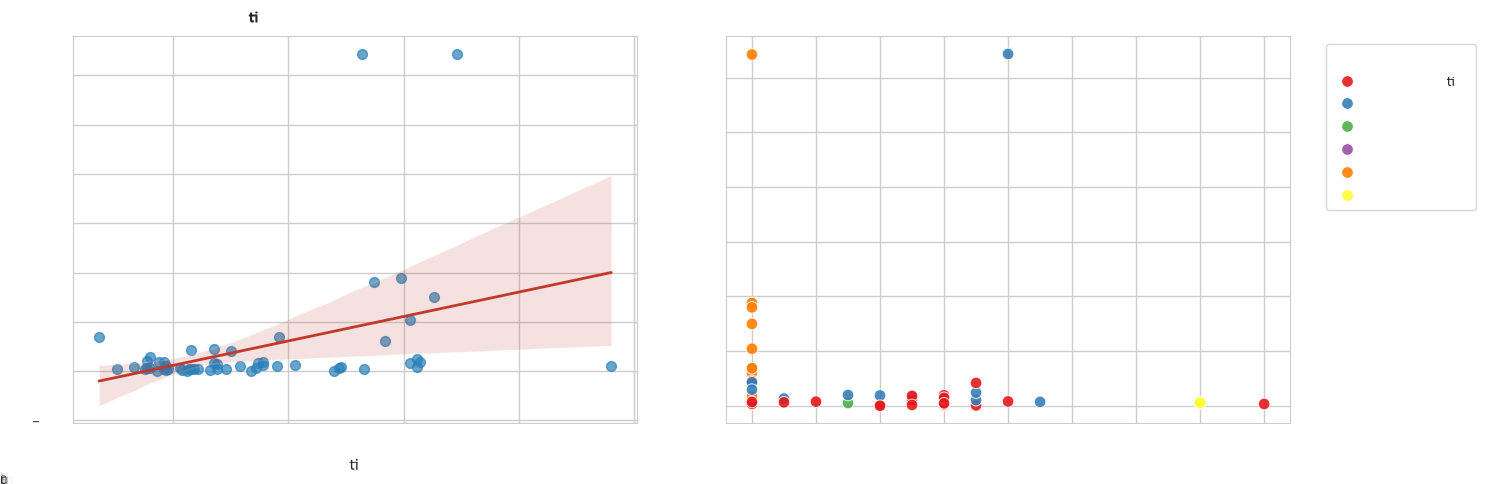

In [12]:
# Visualisasi Scatter Plot & Pembuktian Simpson's Paradox
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Caption Word Count vs Total Interactions
sns.regplot(x='caption_word_count', y='total_interactions', data=df, color='#2980B9',
            scatter_kws={'alpha': 0.7, 's': 50}, line_kws={'color': '#C0392B', 'linewidth': 2}, ax=axes[0])
axes[0].set_title("Jumlah Kata Caption vs Total Interaksi (Spearman rho = +0.381)", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Jumlah Kata Caption (Word Count)")
axes[0].set_ylabel("Total Interaksi")

# 2. Hashtag Count vs Total Interactions (Dengan Hue Akun Kolaborasi)
sns.scatterplot(x='hashtag_count', y='total_interactions', hue='original_account',
                data=df, palette='Set1', s=70, alpha=0.9, ax=axes[1])
axes[1].set_title("Jumlah Tagar vs Interaksi: Fenomena Simpson's Paradox", fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel("Jumlah Tagar (Hashtag Count)")
axes[1].set_ylabel("Total Interaksi")
axes[1].legend(title="Original Account", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()


## 🏆 8. Showcase Postingan Terbaik (Top 10) dan Terendah (Bottom 10)
Identifikasi postingan dengan interaksi tertinggi untuk memetakan formula konten yang berhasil, serta postingan terendah untuk bahan evaluasi.


In [13]:
# Menampilkan Top 10 dan Bottom 10 Postingan
df_sorted = df.sort_values(by='total_interactions', ascending=False).reset_index(drop=True)

print("=== TOP 10 POSTINGAN DENGAN INTERAKSI TERTINGGI ===")
top10 = df_sorted.head(10)[['post_id', 'content_type', 'is_collaboration', 'original_account', 'post_date', 'likes', 'comments', 'total_interactions']]
display(top10)

print("\n=== BOTTOM 10 POSTINGAN DENGAN INTERAKSI TERENDAH ===")
bot10 = df_sorted.tail(10)[['post_id', 'content_type', 'is_collaboration', 'original_account', 'post_date', 'likes', 'comments', 'total_interactions']].sort_values(by='total_interactions', ascending=True)
display(bot10)


=== TOP 10 POSTINGAN DENGAN INTERAKSI TERTINGGI ===


,post_id,content_type,is_collaboration,original_account,post_date,likes,comments,total_interactions
0,DQnklphEi9f,video/reel,True,muhamad.is,2025-11-04,2911,306,3217
1,DDvMbEChsG6,video/reel,True,pecahtelur.id,2024-12-19,3191,21,3212
2,DDk5Lz9KKKL,video/reel,True,pecahtelur.id,2024-12-15,934,7,941
3,DDd0CyvvIbg,video/reel,True,pecahtelur.id,2024-12-13,891,9,900
4,DDxxRE_qUoD,video/reel,True,pecahtelur.id,2024-12-20,747,2,749
5,DDsnn4jpecY,video/reel,True,pecahtelur.id,2024-12-18,521,1,522
6,DDdgFo_xICj,video/reel,True,pecahtelur.id,2024-12-12,340,4,344
7,DaCQc-LEkwR,carousel,True,muhamad.is,2026-06-26,331,11,342
8,DD0V_IjJQaG,video/reel,True,pecahtelur.id,2024-12-21,302,0,302
9,DDzDbeQyCHw,video/reel,False,zahiraccounting,2024-12-20,226,0,226



=== BOTTOM 10 POSTINGAN DENGAN INTERAKSI TERENDAH ===


,post_id,content_type,is_collaboration,original_account,post_date,likes,comments,total_interactions
54,DQww8EzE8tt,video/reel,False,zahiraccounting,2025-11-07,1,0,1
52,Dbr2KN3gZjt,carousel,False,zahiraccounting,2026-08-06,4,0,4
53,DY0oTVmEgxY,image,False,zahiraccounting,2026-05-27,4,0,4
51,DV-ZtDBlKd4,image,False,zahiraccounting,2026-03-17,5,0,5
49,DWIQL4qAWVe,image,False,zahiraccounting,2026-03-21,6,2,8
50,DASqNKZSWKb,video/reel,False,zahiraccounting,2024-09-24,8,0,8
48,DA0MB-BSYKn,video/reel,False,zahiraccounting,2024-10-07,14,0,14
47,DBYHArvSEs3,video/reel,False,zahiraccounting,2024-10-21,17,0,17
46,DNkft1WRs5w,video/reel,False,zahiraccounting,2025-08-20,18,0,18
45,DDb4UG3yD54,video/reel,False,zahiraccounting,2024-12-11,18,0,18


## [RUN] 9. Sintesis Artefak & Rekomendasi Dashboard (Fase 6)
Seluruh 7 artefak data analitik telah diekspor secara berpasangan dalam format CSV (RFC 4180 terenkapsulasi penuh) dan format Excel multi-sheet terformat (`openpyxl`) pada folder `data/final/instagram_analysis/`:

1. `instagram_engagement_metrics.csv` & `.xlsx` (Data level 55 postingan dengan ranking, persentil, dan tier)
2. `instagram_engagement_summary.csv` & `.xlsx` (Statistik deskriptif parametrik & non-parametrik)
3. `instagram_content_type_comparison.csv` & `.xlsx` (Evaluasi format konten)
4. `instagram_collaboration_analysis.csv` & `.xlsx` (Analisis status & rincian akun mitra)
5. `instagram_posting_time_analysis.csv` & `.xlsx` (Dinamika temporal hari, jam tayang, dan tahun)
6. `instagram_caption_hashtag_analysis.csv` & `.xlsx` (Korelasi & audit fenomena perancu tagar)
7. `instagram_top_posts.csv` & `.xlsx` (Showcase 20 postingan performa ekstrem)

### Rekomendasi untuk Dashboard Streamlit (Fase 6):
- **Tab Media Sosial / Instagram**: Tampilkan metrik ringkasan kartu KPI (Total Interaksi: 13.147, Rata-rata: 239.0, Median: 51.0, Outlier Rate: 16.4%).
- **Interactive Slicers**: Berikan filter interaktif untuk membedah postingan berdasarkan `content_type` dan `is_collaboration`.
- **Nuanced Storytelling**: Cantumkan catatan metodologis transparan bahwa metrik views tidak tersedia dan lonjakan pagi dipengaruhi oleh kolaborasi `@pecahtelur.id`.


In [14]:
# Verifikasi Keberadaan Seluruh 7 Pasang Artefak Analisis
import glob
artifacts = glob.glob(os.path.join(os.path.dirname(DATA_PATH), 'instagram_analysis', '*.*'))
print("=== ARTEFAK ANALISIS FASE 5.5 DI DATA/FINAL/INSTAGRAM_ANALYSIS/ ===")
for p in sorted(artifacts):
    size_kb = os.path.getsize(p) / 1024
    print(f"[FILE] {os.path.basename(p):<45} ({size_kb:.1f} KB)")


=== ARTEFAK ANALISIS FASE 5.5 DI DATA/FINAL/INSTAGRAM_ANALYSIS/ ===
[FILE] instagram_caption_hashtag_analysis.csv        (1.8 KB)
[FILE] instagram_caption_hashtag_analysis.xlsx       (10.0 KB)
[FILE] instagram_collaboration_analysis.csv          (1.7 KB)
[FILE] instagram_collaboration_analysis.xlsx         (9.4 KB)
[FILE] instagram_content_type_comparison.csv         (0.8 KB)
[FILE] instagram_content_type_comparison.xlsx        (6.7 KB)
[FILE] instagram_data_quality_audit.csv              (2.5 KB)
[FILE] instagram_data_quality_audit.xlsx             (11.4 KB)
[FILE] instagram_engagement_metrics.csv              (15.1 KB)
[FILE] instagram_engagement_metrics.xlsx             (14.5 KB)
[FILE] instagram_engagement_summary.csv              (0.3 KB)
[FILE] instagram_engagement_summary.xlsx             (6.9 KB)
[FILE] instagram_posting_time_analysis.csv           (1.1 KB)
[FILE] instagram_posting_time_analysis.xlsx          (7.7 KB)
[FILE] instagram_top_posts.csv                       (4.8 KB